# Analyse du dataset de sprites

Ce notebook explore le JSONL préparé localement, sans modifier les données. Les catégories sont des annotations automatiques non vérifiées, pas des vérités terrain. Ouvrir depuis `notebook/dataset/` ou la racine du projet. Nécessite pandas, matplotlib et Jupyter.


In [8]:
from pathlib import Path
import json
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path(p) / "qwen3vl_sprite_training.jsonl" for p in ("iris_sprite_lora_work", "training/iris_sprite_lora_work", "../training/iris_sprite_lora_work", "../../training/iris_sprite_lora_work", "notebook/training/iris_sprite_lora_work")]
path = next((p for p in candidates if p.exists()), None)
if path is None:
    raise FileNotFoundError("JSONL introuvable : lancer depuis training/ ou la racine du projet.")
with path.open(encoding="utf-8") as f:
    rows = [json.loads(line) for line in f if line.strip()]
if not rows:
    raise ValueError("Le JSONL est vide.")
df = pd.json_normalize(rows)
print(f"{len(df)} entrées · {df['asset_id'].nunique()} identifiants uniques · {path}")
display(df.head(3).T)


498 entrées · 498 identifiants uniques · ../../training/iris_sprite_lora_work/qwen3vl_sprite_training.jsonl


,0,1,2
asset_id,4e7203a272af59b647a90108,c170a9344daacebffa42f184,11ec8a6ee8f1b7f52e33f843
free_caption,"Pixel art character sprite, front-facing, stan...","Pixel art character sprite in side view, facin...","A pixel-art sprite, circular in frame, standin..."
training_caption,"sprite, front, standing, pixel art, 96x96\n\nP...","sprite, side, standing, pixel art, 96x96\n\nPi...","sprite, front, standing, pixel art, 96x96\n\nA..."
image,4e7203a272af59b647a90108.png,c170a9344daacebffa42f184.png,11ec8a6ee8f1b7f52e33f843.png
caption_status,candidate_unreviewed,candidate_unreviewed,candidate_unreviewed
review_status,auto_labeled,auto_labeled,auto_labeled
rights_status,unknown,unknown,unknown
source.root,data,data,data
source.relative_path,kirby_super_star/part_02/kirby_super_star-kirb...,dcss_cc0/dcss_cc0-mon-animals-butterfly10.png,metalslug3/metal-slug-3-s32233-p0094.png
tags.asset_type,sprite,sprite,sprite


## Provenance et statuts
Les droits et la qualité des annotations doivent être vérifiés avant utilisation ou partage.


caption_status


,nombre
valeur,
candidate_unreviewed,498



review_status


,nombre
valeur,
auto_labeled,498



rights_status


,nombre
valeur,
unknown,498


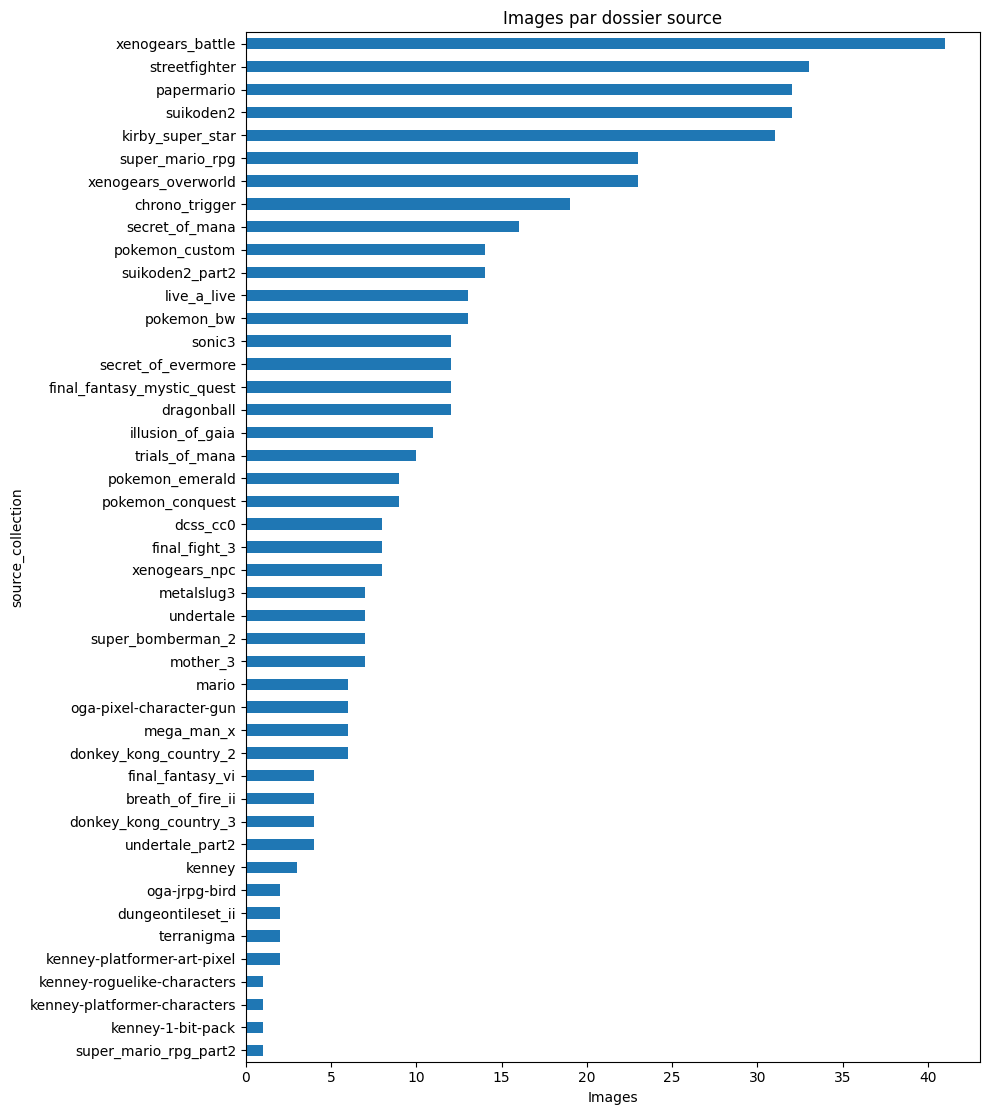

In [9]:
df['source_collection'] = df['source.relative_path'].str.split('/').str[0]
for col in ['caption_status', 'review_status', 'rights_status']:
    print(f"\n{col}")
    display(df[col].value_counts(dropna=False).rename_axis('valeur').to_frame('nombre'))
counts = df['source_collection'].value_counts()
fig, ax = plt.subplots(figsize=(10, max(4, len(counts)*0.25)))
counts.sort_values().plot.barh(ax=ax, title='Images par dossier source'); ax.set_xlabel('Images'); plt.tight_layout(); plt.show()


## Dimensions des images

Les dimensions **sources** sont mesurées sur les fichiers originaux, avant recadrage et redimensionnement. Les dimensions **préparées** sont celles des images réellement utilisées pour l’entraînement. Les images absentes ou illisibles sont comptées séparément. Les dimensions indiquent la taille du fichier, pas nécessairement celle du personnage à l’intérieur.


Images sources : 498 lues, 0 absentes, 0 illisibles


,dimensions,nombre,pourcentage
0,32 × 32,20,4.0
1,96 × 96,13,2.6
2,16 × 16,10,2.0
3,64 × 64,10,2.0
4,48 × 48,6,1.2
...,...,...,...
375,135 × 91,1,0.2
376,137 × 137,1,0.2
377,210 × 336,1,0.2
378,220 × 170,1,0.2


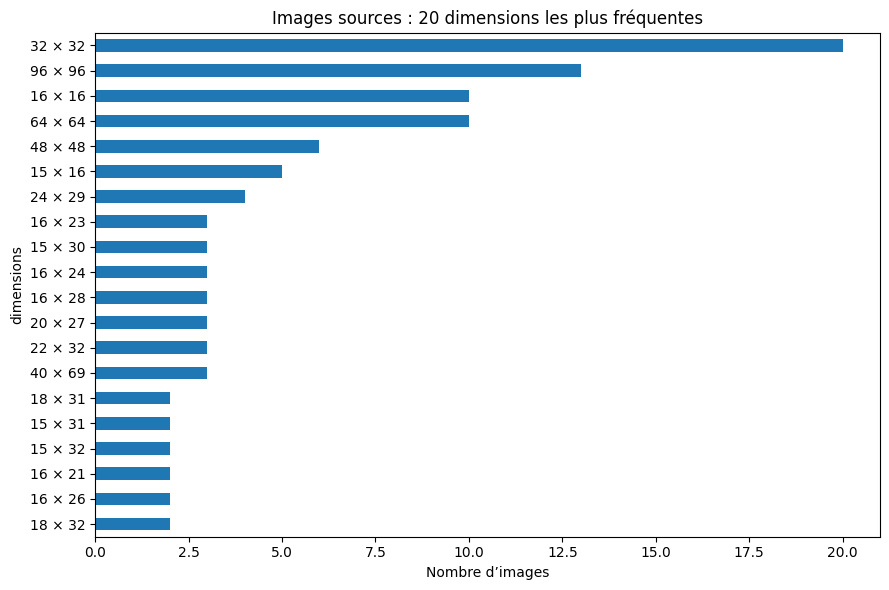

  16 × 16 : 10
  32 × 32 : 20
  96 × 96 : 13
Images préparées : 498 lues, 0 absentes, 0 illisibles


,dimensions,nombre,pourcentage
0,96 × 96,498,100.0


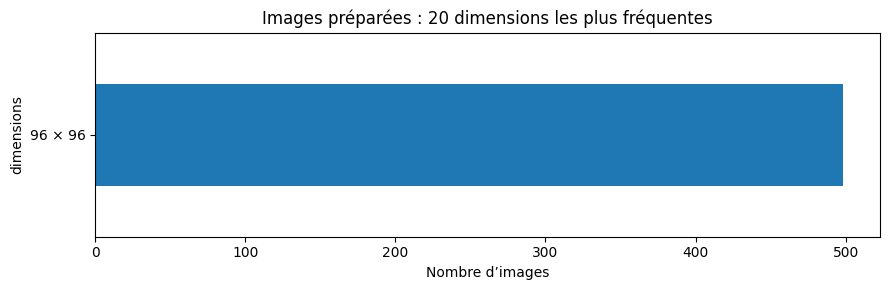

  16 × 16 : 0
  32 × 32 : 0
  96 × 96 : 498


In [3]:
from collections import Counter
from PIL import Image, UnidentifiedImageError

def image_sizes(image_paths):
    counts, missing, unreadable = Counter(), 0, 0
    for image_path in image_paths:
        if not image_path.exists():
            missing += 1
            continue
        try:
            with Image.open(image_path) as im:
                counts[im.size] += 1
        except (OSError, UnidentifiedImageError):
            unreadable += 1
    return counts, missing, unreadable

source_paths = [path.parent / 'source_images' / row['source.root'] / row['source.relative_path'] for _, row in df.iterrows()]
prepared_paths = [path.parent / 'dataset_96' / row['image'] for _, row in df.iterrows()]
for label, image_paths in [('Images sources', source_paths), ('Images préparées', prepared_paths)]:
    counts, missing, unreadable = image_sizes(image_paths)
    print(f"{label} : {sum(counts.values())} lues, {missing} absentes, {unreadable} illisibles")
    if not counts:
        continue
    sizes = pd.DataFrame([{'largeur': w, 'hauteur': h, 'nombre': count} for (w, h), count in counts.items()])
    sizes = sizes.sort_values(['nombre', 'largeur', 'hauteur'], ascending=[False, True, True])
    sizes['pourcentage'] = (100 * sizes['nombre'] / sum(counts.values())).round(1)
    sizes['dimensions'] = sizes['largeur'].astype(str) + ' × ' + sizes['hauteur'].astype(str)
    display(sizes[['dimensions', 'nombre', 'pourcentage']].reset_index(drop=True))
    top = sizes.head(20).set_index('dimensions')['nombre'].sort_values()
    fig, ax = plt.subplots(figsize=(9, max(3, len(top) * 0.3)))
    top.plot.barh(ax=ax, title=label + ' : 20 dimensions les plus fréquentes')
    ax.set_xlabel('Nombre d’images'); plt.tight_layout(); plt.show()
    for side in (16, 32, 96):
        print(f'  {side} × {side} : {counts[(side, side)]}')


## Hiérarchie existante
Les effectifs représentent les étiquettes actuelles, non la composition vérifiée des images. Un chemin peut avoir deux ou trois éléments : les répétitions sont supprimées lors de sa construction.

,nombre,pourcentage
tags.category_path,,
sprite → front → standing,405,81.3
sprite → side → standing,37,7.4
sprite → front → airborne,18,3.6
sprite → front → crouching,12,2.4
sprite → back → standing,11,2.2
sprite → side → airborne,4,0.8
sprite → side → prone,2,0.4
sprite → three_quarter → standing,2,0.4
sprite → front → lying,2,0.4


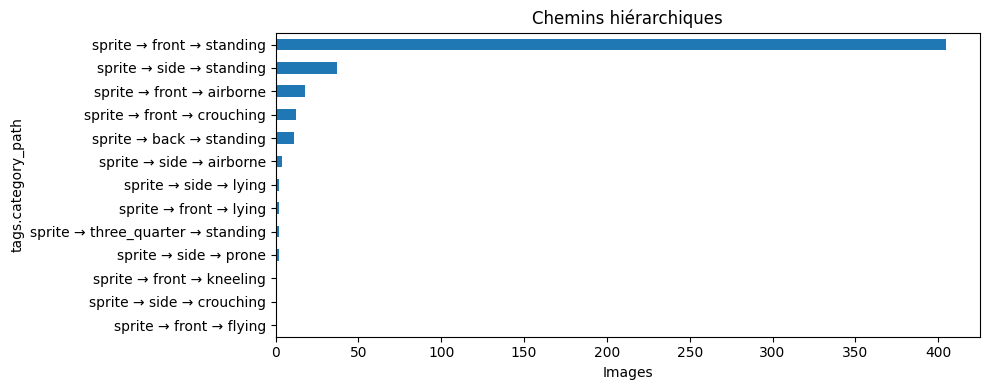


tags.category_level_1


,nombre
valeur,
sprite,498



tags.category_level_2


,nombre
valeur,
front,439
side,46
back,11
three_quarter,2



tags.category_level_3


,nombre
valeur,
standing,455
airborne,22
crouching,13
lying,4
prone,2
flying,1
kneeling,1



tags.asset_type


,nombre
valeur,
sprite,498


Croisement niveaux 1 et 2


tags.category_level_2,back,front,side,three_quarter,All
tags.category_level_1,,,,,
sprite,11,439,46,2,498
All,11,439,46,2,498


In [4]:
paths = df['tags.category_path'].apply(lambda x: ' → '.join(x) if isinstance(x, list) else '(absent)')
counts = paths.value_counts()
display(pd.DataFrame({'nombre': counts, 'pourcentage': (100 * counts / len(df)).round(1)}))
fig, ax = plt.subplots(figsize=(10, 4)); counts.sort_values().plot.barh(ax=ax, title='Chemins hiérarchiques'); ax.set_xlabel('Images'); plt.tight_layout(); plt.show()
for col in ['tags.category_level_1', 'tags.category_level_2', 'tags.category_level_3', 'tags.asset_type']:
    print('\n' + col); display(df[col].value_counts(dropna=False).rename_axis('valeur').to_frame('nombre'))
print('Croisement niveaux 1 et 2')
display(pd.crosstab(df['tags.category_level_1'], df['tags.category_level_2'], margins=True))


## Attributs visuels
Les listes de couleurs et d'équipements sont comptées par présence dans une image ; leur somme peut dépasser le nombre d'images. Les étiquettes restent à contrôler visuellement.


tags.view


,nombre
valeur,
front,439
side,46
back,11
three_quarter,2



tags.facing


,nombre
valeur,
front,440
front_right,37
back,11
front_left,8
back_right,1
left,1



tags.pose


,nombre
valeur,
standing,455
airborne,22
crouching,13
lying,4
prone,2
flying,1
kneeling,1


... (6 outputs left out)


tags.background


,nombre
valeur,
plain white,498



tags.rendering_style


,nombre
valeur,
pixel art,498


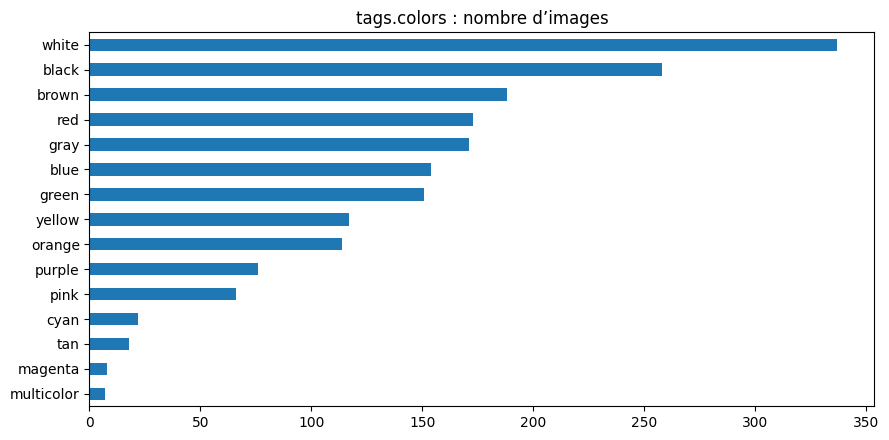

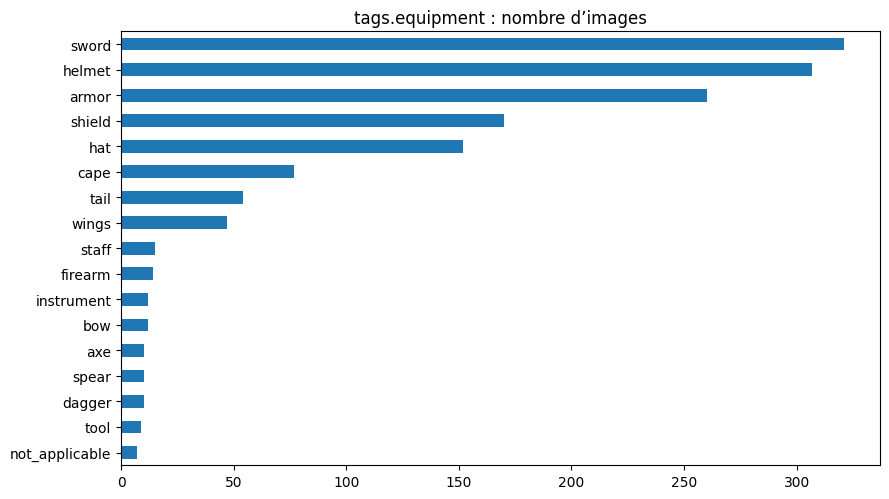

In [5]:
for col in ['tags.view', 'tags.facing', 'tags.pose', 'tags.hair', 'tags.clothing', 'tags.accessories', 'tags.background', 'tags.rendering_style']:
    print('\n' + col); display(df[col].value_counts(dropna=False).rename_axis('valeur').to_frame('nombre'))
for col in ['tags.colors', 'tags.equipment']:
    counter = Counter()
    for value in df[col]:
        counter.update(set(value) if isinstance(value, list) else [str(value)])
    counts = pd.Series(counter).sort_values()
    fig, ax = plt.subplots(figsize=(9, max(3, len(counts)*0.3)))
    counts.plot.barh(ax=ax, title=col + ' : nombre d’images'); plt.tight_layout(); plt.show()


## Audit des rôles et exemples
`enemy` décrit un rôle de jeu, pas une propriété visuelle directement observable. La version actuelle le retire du chemin et de la description ; l’archive originale conserve les annotations initiales. Les autres rôles (`playable`, `npc`, `boss`, `pet`) ont la même limite. Leur présence peut créer des associations visuelles arbitraires. Un futur jeu de légendes devrait privilégier forme, vue, pose, couleurs et équipement vérifiés. Ce notebook n'altère ni les captions ni le modèle existant.

In [6]:
import re
for term in ['enemy', 'playable', 'npc', 'boss', 'pet']:
    prefix = paths.str.contains(fr'\b{term}\b', regex=True, case=False)
    free = df['free_caption'].fillna('').str.contains(fr'\b{term}\b', regex=True, case=False)
    print(f'{term}: {prefix.sum()} chemins, {free.sum()} descriptions libres')
display(df.loc[paths.str.contains(r'\benemy\b', regex=True), ['asset_id', 'source.relative_path', 'tags.category_path', 'free_caption']].head(10))


enemy: 0 chemins, 0 descriptions libres
playable: 0 chemins, 0 descriptions libres
npc: 0 chemins, 0 descriptions libres
boss: 0 chemins, 0 descriptions libres
pet: 0 chemins, 0 descriptions libres


,asset_id,source.relative_path,tags.category_path,free_caption


## Inspection visuelle

Chaque fiche montre l’image source et l’image préparée, leurs dimensions, tous les tags et le prompt complet d’entraînement. Modifiez `N_EXEMPLES` et `GRAINE` ci-dessous pour explorer d’autres images ; mettez `N_EXEMPLES = None` pour afficher tout le dataset. Les fichiers absents ou illisibles sont signalés.



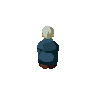


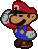
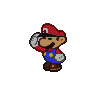


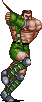
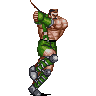


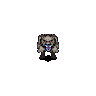


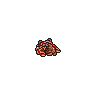


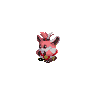


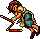
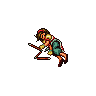


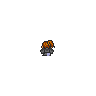


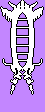
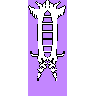


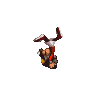


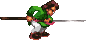
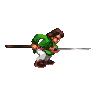


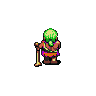

In [7]:
import base64
import html
from io import BytesIO
from IPython.display import HTML, display
from PIL import Image

N_EXEMPLES = 12  # None : toutes les images
GRAINE = 42
sample = df.sample(n=len(df) if N_EXEMPLES is None else min(N_EXEMPLES, len(df)), random_state=GRAINE)

def image_preview(image_path):
    if not image_path.exists():
        return 'Fichier absent', None
    try:
        with Image.open(image_path) as im:
            size = f"{im.width} × {im.height} px"
            preview = im.convert('RGBA')
            preview.thumbnail((256, 256), Image.Resampling.NEAREST)
            buffer = BytesIO()
            preview.save(buffer, format='PNG')
            encoded = base64.b64encode(buffer.getvalue()).decode('ascii')
            return size, encoded
    except OSError:
        return 'Fichier illisible', None

def escape(value):
    return html.escape(str(value))

for index, row in sample.iterrows():
    record = rows[index]
    source_path = path.parent / 'source_images' / row['source.root'] / row['source.relative_path']
    prepared_path = path.parent / 'dataset_96' / row['image']
    previews = []
    for label, image_path in [('Source', source_path), ('Préparée', prepared_path)]:
        size, encoded = image_preview(image_path)
        img = f'<img src="data:image/png;base64,{encoded}" style="width:192px;height:192px;object-fit:contain;image-rendering:pixelated;background:#eee">' if encoded else ''
        previews.append(f'<div><strong>{escape(label)} · {escape(size)}</strong><br>{img}</div>')
    tags = json.dumps(record.get('tags', {}), ensure_ascii=False, indent=2)
    caption = record.get('training_caption', '')
    free_caption = record.get('free_caption', '')
    display(HTML(f"""
    <div style="border:1px solid #bbb;border-radius:8px;padding:16px;margin:16px 0">
      <h3>{escape(row['asset_id'])}</h3>
      <p><strong>Source :</strong> {escape(row['source.relative_path'])}</p>
      <div style="display:flex;gap:24px;flex-wrap:wrap">{''.join(previews)}</div>
      <p><strong>Tags :</strong></p><pre style="white-space:pre-wrap">{escape(tags)}</pre>
      <p><strong>Prompt d’entraînement complet :</strong></p><pre style="white-space:pre-wrap">{escape(caption)}</pre>
      <p><strong>Description libre :</strong></p><pre style="white-space:pre-wrap">{escape(free_caption)}</pre>
    </div>
    """))


## Analyse des annotations Qwen3.8 Gyro-S

Cette section lit le JSONL de taxonomie v3.4 et présente la répartition des valeurs prédites par le modèle. Elle affiche ensuite des exemples tirés au hasard avec leurs images, leurs captions et leurs taxonomies. Les étiquettes sont automatiques et restent à vérifier. Si une image n’est pas dans le cache local, le notebook peut la récupérer depuis le dataset Hugging Face privé (connexion HF requise).


In [ ]:
from pathlib import Path
import json
import os
import random
import base64
import html
from io import BytesIO
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import HTML, display

# Retrouve les fichiers depuis la racine du projet ou depuis notebook/dataset/.
cwd = Path.cwd().resolve()
project_roots = [p for p in (cwd, *cwd.parents) if (p / 'notebook/dataset').is_dir()]
project_root = project_roots[0] if project_roots else cwd
QWEN38_JSONL = project_root / 'notebook/dataset/taxonomy/taxonomy_work/annotations_v3_4_full_color.jsonl'
if not QWEN38_JSONL.is_file():
    raise FileNotFoundError(f'Annotations Qwen3.8 introuvables : {QWEN38_JSONL}')

# Lit uniquement les lignes JSON terminées, au cas où le processus d’annotation écrit encore.
qwen_rows = []
with QWEN38_JSONL.open('rb') as stream:
    while True:
        line = stream.readline()
        if not line or not line.endswith(b'\n'):
            break
        if line.strip():
            qwen_rows.append(json.loads(line))
qwen_rows = [r for r in qwen_rows if 'qwen3.8' in str(r.get('model', '')).lower() and 'gyro' in str(r.get('model', '')).lower()]
if not qwen_rows:
    raise ValueError('Aucune ligne Qwen3.8 Gyro-S trouvée dans le fichier.')
print(f"{len(qwen_rows):,} annotations Qwen3.8 Gyro-S · {len({r.get('asset_id') for r in qwen_rows}):,} asset_id uniques · {QWEN38_JSONL}")

# Les taxonomies scalaires comptent les images; les listes comptent la présence de chaque valeur par image.
taxonomy_fields = [
    'asset_type', 'subject_type', 'view', 'pose', 'action',
    'background_type', 'render_family', 'body_plan', 'wings',
    'background_scene', 'visual_quality', 'dominant_color_families',
    'palette_size', 'palette_temperature', 'palette_structure', 'palette_contrast',
]
fig, axes = plt.subplots(4, 4, figsize=(22, 20))
for ax, field in zip(axes.flat, taxonomy_fields):
    counts = Counter()
    for row in qwen_rows:
        value = row.get('labels', {}).get(field)
        values = value if isinstance(value, list) else [value]
        counts.update({str(v) for v in values if v not in (None, '', 'unknown', 'not_applicable')})
    top = counts.most_common(10)
    if top:
        names, values = zip(*top)
        ax.barh(list(names)[::-1], list(values)[::-1], color='#5686c5')
        ax.set_xlim(0, max(values) * 1.2)
    ax.set_title(field, loc='left', fontsize=10, fontweight='bold')
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
axes.flat[-1].axis('off')
fig.suptitle('Répartition des taxonomies Qwen3.8 Gyro-S · 10 valeurs les plus fréquentes par champ', fontsize=15, y=1.01)
fig.tight_layout()
plt.show()

for field in ('visual_quality', 'need_rework', 'review_status'):
    counts = Counter(row.get('labels', {}).get(field) if field == 'visual_quality' else row.get(field) for row in qwen_rows)
    print(f'\n{field}')
    display(pd.DataFrame(counts.most_common(), columns=['valeur', 'images']))


### Exemples aléatoires annotés

Change `N_EXEMPLES_QWEN` et `GRAINE_QWEN` pour obtenir un autre échantillon. L’aperçu tente d’abord le cache d’images du workspace, puis Hugging Face pour les images manquantes.


In [ ]:
from huggingface_hub import hf_hub_download

N_EXEMPLES_QWEN = 12
GRAINE_QWEN = 42
TELECHARGER_IMAGES_HF = True  # Mettre False pour limiter l’aperçu aux images déjà en cache.
HF_DATASET_REPO = 'ethanzxv/pixelart-dataset'
HF_TOKEN = os.environ.get('HF_TOKEN') or os.environ.get('HUGGINGFACE_HUB_TOKEN') or True

cache_roots = [project_root / 'notebook/training/iris_sprite_lora_work/source_images']
if 'path' in globals() and path is not None:
    cache_roots.insert(0, Path(path).parent / 'source_images')
sample_qwen = random.Random(GRAINE_QWEN).sample(qwen_rows, min(N_EXEMPLES_QWEN, len(qwen_rows)))
cards = []
for row in sample_qwen:
    source = row.get('source', {})
    relative_path = str(source.get('relative_path', '')).replace('\\', '/')
    root_name = str(source.get('root', 'data'))
    image_path = next((root / root_name / relative_path for root in cache_roots if (root / root_name / relative_path).is_file()), None)
    if image_path is None and TELECHARGER_IMAGES_HF and relative_path:
        try:
            image_path = Path(hf_hub_download(repo_id=HF_DATASET_REPO, repo_type='dataset', filename=f'data/{relative_path}', token=HF_TOKEN))
        except Exception as exc:
            image_path = None
            image_error = str(exc)[:180]
    else:
        image_error = ''
    image_html = '<p><em>Image indisponible dans le cache et sur Hugging Face.</em></p>'
    if image_path is not None and image_path.is_file():
        try:
            with Image.open(image_path) as im:
                original_size = f'{im.width} × {im.height} px'
                preview = im.convert('RGBA')
                preview.thumbnail((256, 256), Image.Resampling.NEAREST)
                buffer = BytesIO()
                preview.save(buffer, format='PNG')
            encoded = base64.b64encode(buffer.getvalue()).decode('ascii')
            image_html = f'<img src="data:image/png;base64,{encoded}" style="width:192px;height:192px;object-fit:contain;image-rendering:pixelated;background:#eee"><p>{original_size}</p>'
        except OSError:
            image_error = 'Fichier image illisible.'
    labels_json = html.escape(json.dumps(row.get('labels', {}), ensure_ascii=False, indent=2))
    caption = html.escape(str(row.get('caption_candidate', '')))
    asset_id = html.escape(str(row.get('asset_id', 'sans id')))
    quality = html.escape(str(row.get('labels', {}).get('visual_quality', 'inconnue')))
    need_rework = html.escape(str(row.get('need_rework', 'inconnu')))
    cards.append(
        f'<article style="flex:1;min-width:270px;max-width:380px;padding:12px;border:1px solid #ccc;border-radius:8px">'
        f'<h4>{asset_id}</h4>{image_html}<p><b>Source :</b> {html.escape(relative_path)}</p>'
        f'<p><b>Qualité :</b> {quality} · <b>Rework :</b> {need_rework}</p>'
        f'<p><b>Caption Qwen :</b> {caption}</p>'
        f'<details><summary>Taxonomies complètes</summary><pre style="white-space:pre-wrap;font-size:11px">{labels_json}</pre></details></article>'
    )
display(HTML('<div style="display:flex;gap:12px;flex-wrap:wrap;align-items:flex-start">' + ''.join(cards) + '</div>'))
